In [1]:
import os, os.path as op, glob
from copy import deepcopy
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from nilearn.plotting import plot_stat_map
from nilearn.datasets import load_mni152_template
from nilearn.glm.first_level import make_first_level_design_matrix

# Fill-in the path to the project folder
data_path = os.path.abspath("")
fig_dir = op.join(data_path, 'figures')
os.makedirs(fig_dir, exist_ok=True)

In [2]:
img = nib.load(op.join(data_path, 'derivatives', 'tfMRI_LANGUAGE_LR_moco_smoothed-8mm.nii.gz'))
affine = img.affine
data = np.asanyarray(img.dataobj)
data.shape

(91, 109, 91, 315)

In [3]:
# Make variables:
# 'vol_shape' for shape of volumes
# 'n_vols' for number of volumes
vol_shape = np.array(data.shape[:3])
n_vols = data.shape[3]

In [4]:
# Make variables:
# 'vol_shape' for shape of volumes
# 'n_vols' for number of volumes
vol_shape = np.array(data.shape[:3])
n_vols = data.shape[3]

In [5]:
# Note: In our case the background is encoded as <= 500
# you can consider that the first volume's background
# voxels are the same as all following volumes
slice_non_background = data[..., 0] > 500
# Vectorize : Taking only non-zero voxels into a vector
# (NOTE: that the order is important)
samples = data[slice_non_background]
samples.shape

(280554, 315)

In [6]:
# Calculate the mean across columns
spatial_means = samples.mean(axis=1)
# Row means copied n_vols times so that we substract for each timepoint the spatial mean
row_means = np.tile(spatial_means[:, None], (1, n_vols))
# Subtract the means for each row, put the result into X
X = samples - row_means



In [7]:
X.shape

(280554, 315)

In [8]:

X_kmeans = deepcopy(X)

In [9]:
max_nb_clusters = 16
avg_dist_samples = []
for nb_cluster in range(1, max_nb_clusters):
    kmeans = KMeans(n_clusters=nb_cluster, random_state=0, n_init="auto").fit(X_kmeans.T)
    avg_dist_samples.append(kmeans.inertia_)

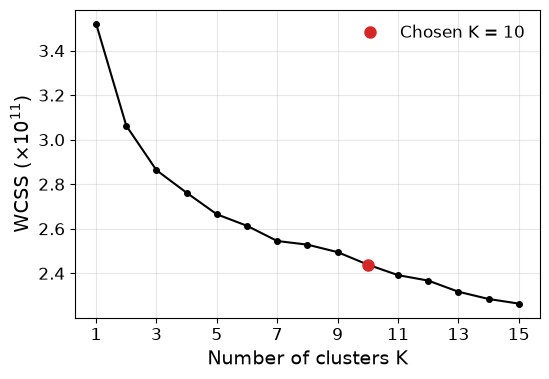

In [10]:
K = np.arange(1, len(avg_dist_samples) + 1)
wcss = np.array(avg_dist_samples) / 1e11

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(K, wcss, 'o-', c='k', ms=4)
ax.plot(10, wcss[9], 'o', c='tab:red', ms=8, label='Chosen K = 10')
ax.set_xlabel('Number of clusters K', size=14)
ax.set_ylabel(r'WCSS ($\times 10^{11}$)', size=14)
ax.set_xticks(K[::2])
ax.tick_params(labelsize=12)
ax.legend(fontsize=12, frameon=False)
ax.grid(True, alpha=0.3)
fig.savefig(op.join(fig_dir, 'kmeans_elbow.png'), dpi=300, bbox_inches='tight')
plt.show()

In [10]:
nb_clusters = 10 # The number of clusters you want (choose it from the elbow plot)
kmeans = KMeans(n_clusters=nb_clusters, random_state=0, n_init="auto").fit(X_kmeans.T)

kmeans_clusters = [] # List of spatial components (you should have in the list volumes)
for center in kmeans.cluster_centers_:
    vol = np.zeros(tuple(vol_shape))
    vol[slice_non_background] = center
    kmeans_clusters.append(vol)

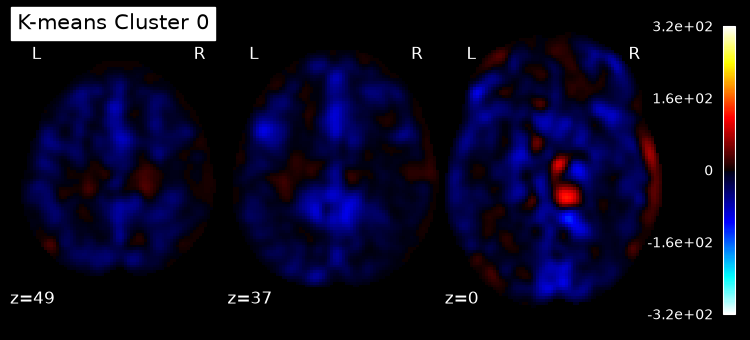

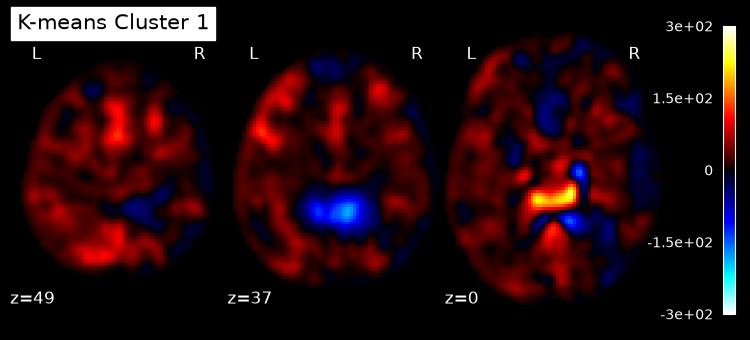

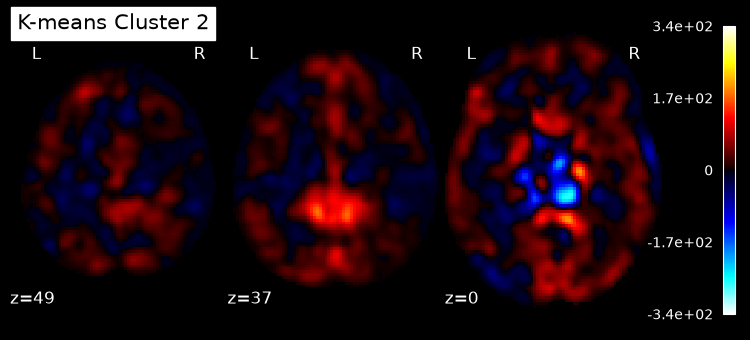

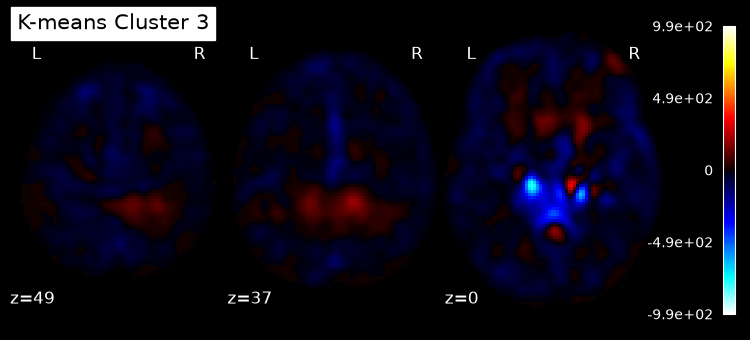

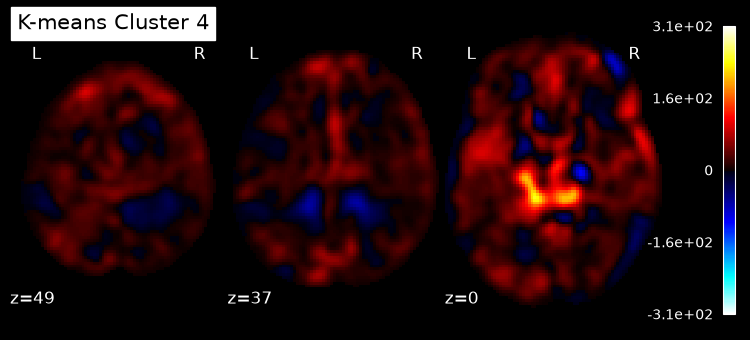

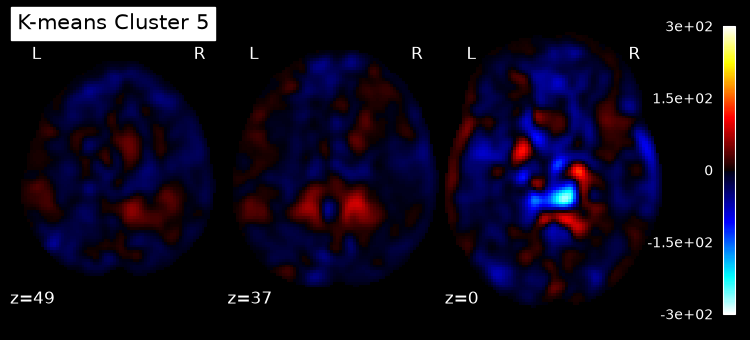

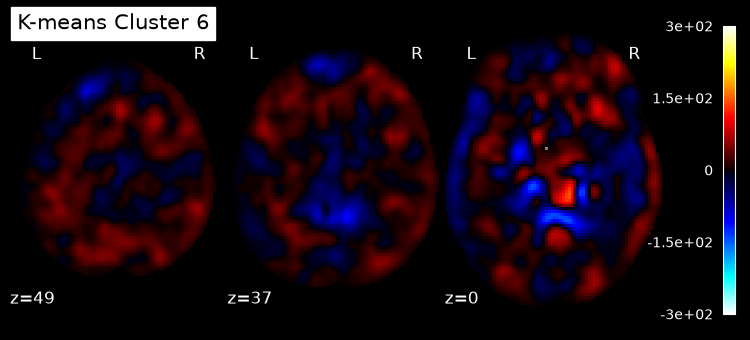

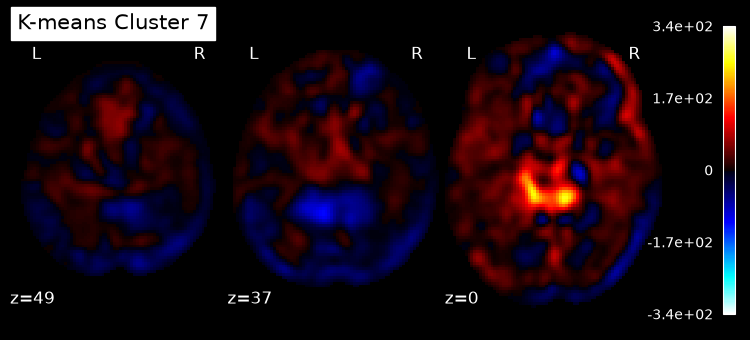

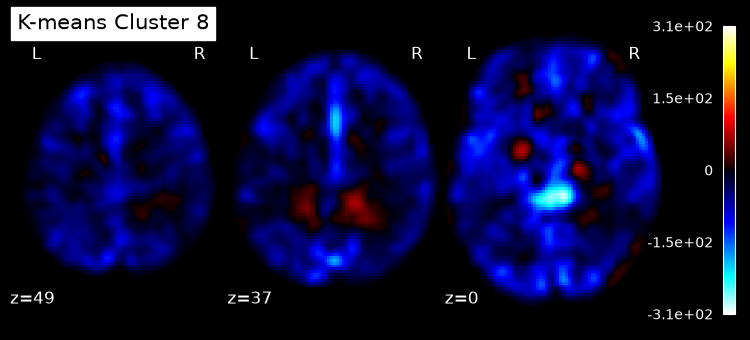

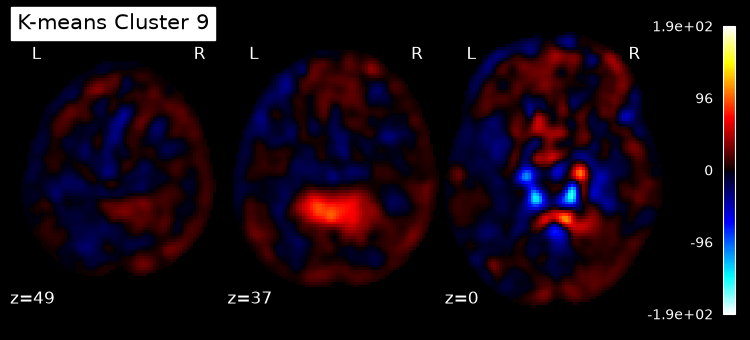

In [11]:
for visual_idx in range(nb_clusters):
    plot_stat_map(nib.Nifti1Image(kmeans_clusters[visual_idx], affine), bg_img=load_mni152_template(),
                  threshold=1e-3, display_mode='z', cut_coords=[49,37,00], black_bg=True,
                  title=f'K-means Cluster {visual_idx}')
    plt.savefig(op.join(fig_dir, f'kmeans_cluster_{visual_idx}.png'), dpi=300, bbox_inches='tight')
    plt.show()

In [12]:
# Correlation with GLM regressors
tr = float(img.header.get_zooms()[3])
start_vol = 1 # Number of volumes removed in the functional preprocessing

events = pd.read_csv(glob.glob(op.join(data_path, '**', 'tfMRI_LANGUAGE_LR_task_onsets.csv'), recursive=True)[0])
# Shift the onsets because the first volumes were removed
events['onset'] = events['onset'] - start_vol * tr

frame_times = np.arange(n_vols) * tr
design_mat = make_first_level_design_matrix(frame_times, events, hrf_model='spm', drift_model=None)
regressors = [c for c in design_mat.columns if c != 'constant']

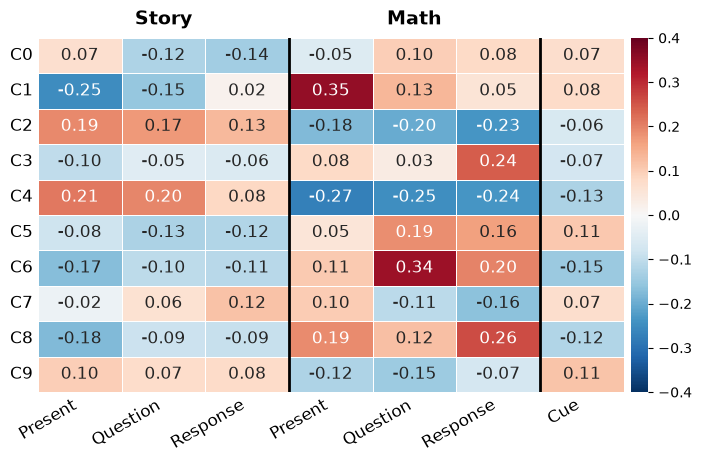

In [13]:
# Binary time course of cluster membership (1 if timepoint belongs to cluster c, 0 otherwise)
binary_tc = pd.DataFrame({f'Cluster {c}': (kmeans.labels_ == c).astype(float)
                          for c in range(min(10, nb_clusters))})

# Correlation between cluster time courses and GLM regressors
corr = pd.concat([binary_tc, design_mat[regressors].reset_index(drop=True)], axis=1).corr()
corr = corr.loc[binary_tc.columns, regressors]

# ---------- Plot ----------
order = ['present_story', 'question_story', 'response_story',
         'present_math', 'question_math', 'response_math', 'cue']
labels = ['Present', 'Question', 'Response',
          'Present', 'Question', 'Response', 'Cue']
C = corr[order].copy()
C.index = [f'C{i}' for i in range(len(C))]
C.columns = labels
lim = np.ceil(np.abs(C.values).max() * 10) / 10

fig, ax = plt.subplots(figsize=(9, 4.6))
sns.heatmap(C, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-lim, vmax=lim, center=0,
            annot_kws={'size': 12}, linewidths=0.5, linecolor='white',
            cbar_kws={'pad': 0.01}, ax=ax)
ax.axvline(3, color='black', lw=2); ax.axvline(6, color='black', lw=2)
ax.text(1.5, -0.25, 'Story', ha='center', va='bottom', fontsize=14, weight='bold')
ax.text(4.5, -0.25, 'Math', ha='center', va='bottom', fontsize=14, weight='bold')
ax.tick_params(axis='both', labelsize=12, length=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
cbar = ax.collections[0].colorbar

fig.savefig(op.join(fig_dir, 'kmeans_glm_correlation.png'), dpi=300,
            bbox_inches='tight', pad_inches=0.02)
plt.show()

#CLaude code

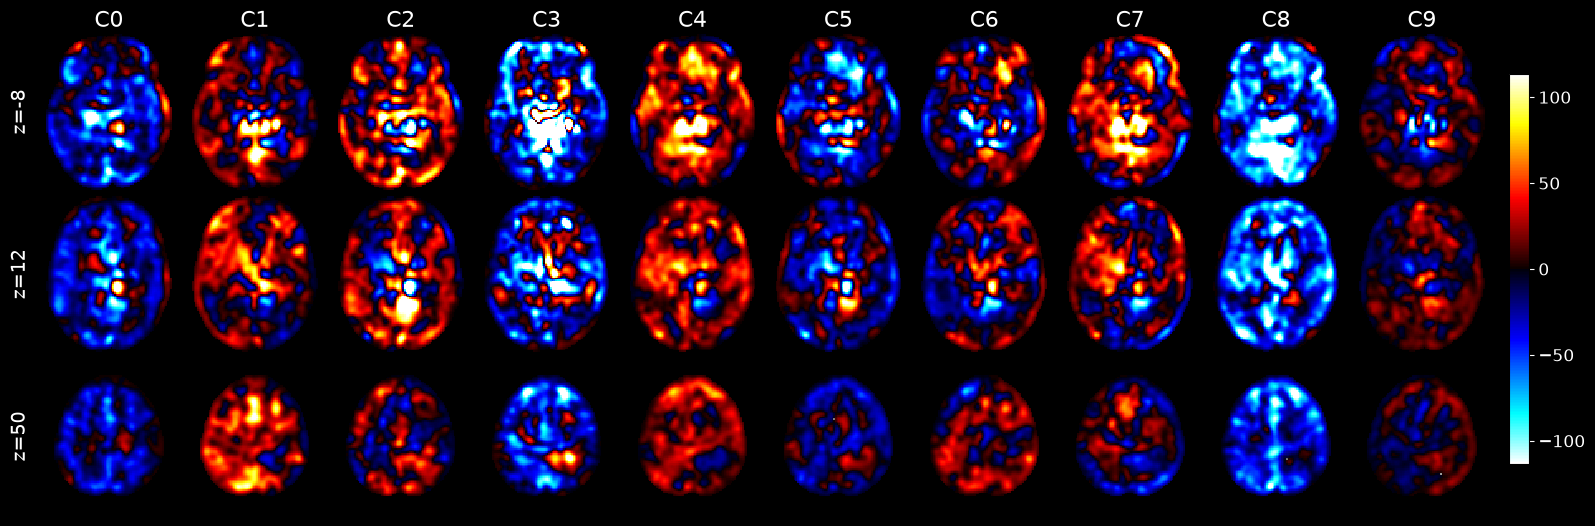

In [14]:
from matplotlib import cm, colors as mcolors

bg = load_mni152_template()
z_levels = [-8, 12, 50] # Same as GLM

# Shared colour scale: median of the clusters' 99th percentiles
# (keeps normal clusters bright; very high-amplitude clusters saturate)
vmax = np.median([np.percentile(np.abs(v[v != 0]), 99) for v in kmeans_clusters])

fig, axes = plt.subplots(len(z_levels), nb_clusters, figsize=(16, 5.2), facecolor='black',
                         gridspec_kw={'wspace': 0.02, 'hspace': 0.02})
plt.subplots_adjust(left=0.03, right=0.94, top=0.93, bottom=0)

for i in range(nb_clusters):
    img = nib.Nifti1Image(kmeans_clusters[i], affine)
    for r, z in enumerate(z_levels):
        plot_stat_map(img, bg_img=bg, axes=axes[r, i], display_mode='z', cut_coords=[z],
                      threshold=1e-3, vmax=vmax, cmap='cold_hot', black_bg=True,
                      annotate=False, draw_cross=False, colorbar=False)
    axes[0, i].set_title(f'C{i}', color='white', fontsize=16, pad=4)   # cluster label
    axes[0, i].axis('on'); axes[0, i].set_xticks([]); axes[0, i].set_yticks([])
    for s in axes[0, i].spines.values():
        s.set_visible(False)

for r, z in enumerate(z_levels):                                        # slice labels
    pos = axes[r, 0].get_position()
    fig.text(pos.x0 - 0.005, (pos.y0 + pos.y1) / 2, f'z={z}', color='white',
             fontsize=14, rotation=90, ha='right', va='center')

cax = fig.add_axes([0.95, 0.1, 0.012, 0.75])                           # one shared colour bar
sm = cm.ScalarMappable(norm=mcolors.Normalize(-vmax, vmax), cmap='cold_hot')
cb = fig.colorbar(sm, cax=cax)
cb.ax.tick_params(colors='white', labelsize=12)

fig.savefig(op.join(fig_dir, 'kmeans_maps.png'), dpi=300,
            bbox_inches='tight', pad_inches=0.02, facecolor='black')
plt.show()

# Claude code